# Finance Scenarios -- 5. Model Validation

Would you put a capital number on these scenarios? A validator asks two things of a scenario generator: does a
run behave like the economy it describes, and would the model have held what actually happened, had it been
fitted in the past on only what was known then? This notebook asks both of the default factor set, with the calibration behind the README,
and shows where the answer is no.

In [1]:
import matplotlib.pyplot as plt

from financescenarios import CalibrationResult, Scenarios, set_display

set_display(decimals=4)
plt.rcParams["figure.dpi"] = 80  # keeps the two six-panel charts below light

## Step 1: the run

The README's calibration of 2026-10-17, saved with the repository, simulated 30 years ahead with 1,000
scenarios, so every scenario gives 30 year-end observations to set against decades of history.

In [2]:
scenarios = Scenarios.from_profiles(
    settings="default",
    factor_set="default",
    api_key="FINANCIAL_MODELING_PREP_KEY",  # replace with your actual API key
    fred_api_key="FRED_KEY",  # optional, replace with your actual FRED key or leave it out
)

# The README's calibration, saved with the repository; scenarios.calibrate() fits a fresh one
calibration = CalibrationResult.load("../docs/assets/readme/calibration.json")
result = scenarios.simulate(calibration=calibration, n_simulations=1000, years=30, seed=42)

## Step 2: do the factors move together the way the economy does?

Each relationship is measured the same way on decades of history and on every scenario.

In [3]:
relationships = scenarios.check_relationships(result)
relationships.select("relationship", "region", "status", "history", "simulated_median")

relationship,region,status,history,simulated_median
str,str,str,f64,f64
"""Policy rate reacts to inflation""","""United States""","""pass""",0.4522,0.2406
"""Policy rate reacts to unemployment""","""United States""","""warn""",-0.5787,-0.2202
"""Rates near neutral at target, higher above it""","""United States""","""pass""",0.0570,0.0356
"""Phillips curve""","""United States""","""warn""",-0.5923,-0.2916
"""Bear markets come with rising unemployment""","""United States""","""warn""",-0.4096,-0.1544
"""Long rate moves with the short rate""","""United States""","""pass""",0.3303,0.5862
"""Inverted curve precedes higher unemployment""","""United States""","""warn""",-0.6712,-0.2421
"""Real equity returns fall with high inflation""","""United States""","""warn""",-0.1525,-0.0701
"""Higher rates slow house prices""","""United States""","""pass""",-0.9628,-0.9308


15 of the 26 relationships pass and 11 warn; none fails. The US policy rate answers inflation with a slope of
0.24 against history's 0.45, and the long rate following the short rate (0.59 against 0.33) and higher rates
slowing house prices (-0.93 against -0.96) come out in history's direction. What warns is mostly a link that is
there but weaker than in history: unemployment moves the policy rate less than half as strongly in all three
economies (-0.22 against -0.58 in the US), the US Phillips curve is about half as steep (-0.29 against -0.59),
bear markets come with rising unemployment at -0.15 against -0.41, and an inverted US curve foreshadows higher
unemployment at -0.24 against -0.67. The two currency rows pass with the opposite sign to history only because
history's own slope is too uncertain to tell.

## Step 3: does each factor stay within what history has seen?

Each factor's range, largest one-year moves, drawdowns and long stretches, read at year ends against its
longest record; `summary=True` gives one row per factor with what warns or fails.

In [4]:
scenarios.check_realism(result, summary=True)

factor,kind,status,flagged
str,str,str,str
"""united_states_short_rate""","""short rate""","""fail""","""largest one-year fall (fail, tail too thin)"""
"""united_states_long_rate""","""long rate""","""warn""","""largest one-year rise (warn)"""
"""eurozone_short_rate""","""short rate""","""fail""","""lowest level (warn, tail too fat); highest level (fail, tail too thin); largest one-year rise (fail, tail too thin); largest one-year fall (fail, tail too thin)"""
"""eurozone_long_rate""","""long rate""","""fail""","""highest level (fail, tail too thin); longest curve inversion (warn)"""
"""united_kingdom_short_rate""","""short rate""","""fail""","""highest level (fail); largest one-year rise (fail); largest one-year fall (warn); longest stretch at the zero lower bound (fail)"""
"""united_kingdom_long_rate""","""long rate""","""fail""","""highest level (warn); largest one-year fall (fail, tail too thin); longest curve inversion (fail)"""
"""united_states_inflation""","""inflation""","""warn""","""lowest level (warn, tail too fat); highest level (warn, tail too thin); largest one-year rise (warn)"""
"""eurozone_inflation""","""inflation""","""warn""","""lowest level (warn, tail too thin); highest level (warn, tail too thin)"""
"""united_kingdom_inflation""","""inflation""","""fail""","""lowest level (fail, tail too fat); largest one-year rise (warn)"""


No factor passes every test: 8 of the 23 warn and 15 fail. Most flags are tails that are too thin: over 30
years the scenarios reach history's record years less often than history's own windows did, for the rates and
unemployment of all three economies, house prices, Japanese stocks and crude oil's largest one-year rise. A few go
the other way, such as low inflation in the US and the UK ("tail too fat"). No factor reaches a state no economy
can be in.

## Step 4: are the fitted parameters ones the real world could produce?

Guardrails on the fitted parameters themselves: fits at a bound, half-lives, long-run levels against history's
range, volatility against the history behind the fit, and equity crisis regimes against the same model on the
long US record. Only the flagged ones are shown.

In [5]:
scenarios.check_parameters(result, flagged_only=True)

factor,check,parameter,status,value,yardstick,fit,detail
str,str,str,str,f64,str,str,str
"""eurozone_unemployment""","""long-run level""","""long_run_mean""","""warn""",0.0716,"""OECD unemployment (France): 7.20% to 10.90%""","""UnemploymentParams: on OECD France data from 2000, linked to eurozone_inflation""","""settles at 7.16%, outside history's 7.20% to 10.90%"""
"""united_kingdom_short_rate""","""volatility""","""volatility""","""warn""",1.5588,"""its calibration history, step moves""","""PolicyRuleParams: hull_white, on OECD United Kingdom monthly data from 2000, a taylor rule on united_kingdom_inflation and united_kingdom_unemployment""","""simulated volatility 1.56x the realised one"""
"""japan""","""regime share""","""stationary_distribution[0]""","""warn""",0.4481,"""the same model fitted on Shiller's US total return since 1871: 0.143""","""RegimeParams: regime_switching, on EWJ monthly data from 2000, 2 regimes, regimes timed on the japan long history, earning the short rate plus a long-run premium""","""long-run share in the crisis regime: 0.448 against 0.143 in the long record, 3.14x"""
"""japan""","""regime duration""","""expected stay in regime 1 (years)""","""warn""",1.1569,"""the same model fitted on Shiller's US total return since 1871: 2.87""","""RegimeParams: regime_switching, on EWJ monthly data from 2000, 2 regimes, regimes timed on the japan long history, earning the short rate plus a long-run premium""","""expected stay in the calm regime, in years: 1.16 against 2.87 in the long record, 0.40x"""


Four guardrails warn and none fails. Euro-area unemployment settles at 7.16%, just below the 7.20% to 10.90% of
the French history it was fitted on; the UK short rate swings 1.56 times its calibration history; and Japan's
equity regimes are furthest from the long US record, in the crisis regime 44.8% of the time against 14.3%, with
calm spells of 1.16 years against 2.87.

## Step 5: back to the end of 2007

Now the harder test. Every series is cut at 31 December 2007, the model is fitted on the 26 years before it,
and 1,000 scenarios run five years ahead from that day's values; the orange line is what happened. The
published values the fit reads besides the data, such as the neutral rate in the policy rule, are the ones
known that day.

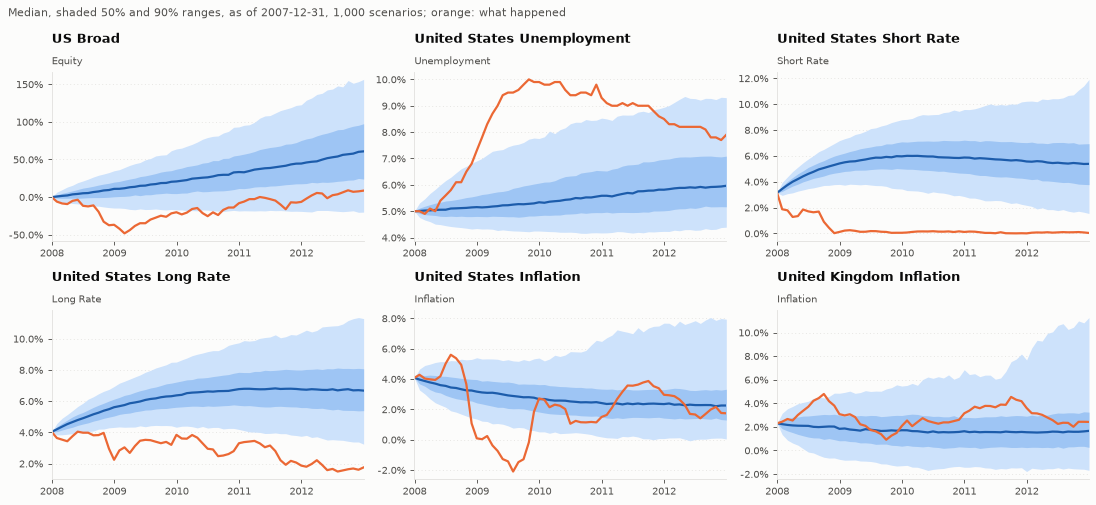

In [6]:
factors = [
    "us_broad",
    "united_states_unemployment",
    "united_states_short_rate",
    "united_states_long_rate",
    "united_states_inflation",
    "united_kingdom_inflation",
]
crisis = scenarios.out_of_sample(as_of="2007-12-31", years=5, n_simulations=1000, seed=42, factors=factors)
crisis.plot(factors)

In [7]:
crisis.table.select("factor", "date", "realized", "p5", "p50", "p95", "pit")

factor,date,realized,p5,p50,p95,pit
str,date,f64,f64,f64,f64,f64
"""united_states_inflation""",2008-12-31,0.0009,0.0136,0.0317,0.0540,0.0070
"""united_states_inflation""",2009-12-31,0.0272,0.0051,0.0267,0.0538,0.5180
"""united_states_inflation""",2010-12-31,0.0150,0.0018,0.0241,0.0648,0.2510
"""united_states_inflation""",2011-12-31,0.0296,0.0007,0.0235,0.0768,0.6790
"""united_states_inflation""",2012-12-31,0.0174,0.0005,0.0225,0.0795,0.3610
"""united_kingdom_inflation""",2008-12-31,0.0308,-0.0075,0.0183,0.0485,0.7710
"""united_kingdom_inflation""",2009-12-31,0.0207,-0.0130,0.0172,0.0546,0.5730
"""united_kingdom_inflation""",2010-12-31,0.0315,-0.0143,0.0163,0.0685,0.7910
"""united_kingdom_inflation""",2011-12-31,0.0360,-0.0179,0.0155,0.0768,0.8270


In [8]:
crisis.scores.select("factor", "coverage_50", "coverage_90", "pit_mean", "crps_skill")

factor,coverage_50,coverage_90,pit_mean,crps_skill
str,f64,f64,f64,f64
"""united_states_inflation""",0.8000,0.8000,0.3632,0.6258
"""united_kingdom_inflation""",0.4000,1.0000,0.7170,-0.2460
"""united_states_short_rate""",0.0000,0.0000,0.0020,-0.4967
"""united_states_long_rate""",0.0000,0.0000,0.0080,-1.1081
"""united_states_unemployment""",0.0000,0.4000,0.9446,0.3893
"""us_broad""",0.0000,0.6000,0.0800,-0.9682


The financial crisis falls largely outside the cloud, because of its speed. US unemployment reached 7.3% at
the end of 2008 and 9.9% at the end of 2009, while 1 in 20 scenarios went above 6.91% and 7.76%; only by 2011,
at 8.5%, was it back inside the 90% band. The short rate was cut to 0.11% within the year against a 5th
percentile of 3.79% and stayed below the band through 2012; the 10-year rate fell to 2.24% against 4.32% and
stayed below it too. US stocks were down 36.8% by the end of 2008 against a 5th percentile of -14.55%. US
inflation dipped below the band at the end of 2008 (0.09%) and came back inside it; UK inflation stayed inside
throughout. In the scores, the 90% band held none of the five years for either rate, two for unemployment and
three for stocks, and on CRPS the scenarios lose to a no-change forecast for stocks, both rates and UK
inflation.

What did the fit know? Each value the US policy rule read is in the run's notes, with its source:

In [9]:
for note in crisis.notes:
    if note.startswith("united_states_short_rate:"):
        print(note)

united_states_short_rate: EIOPA long-run anchor switched off, the Finance Toolkit has no EIOPA curve by then (its releases start in January 2023)
united_states_short_rate: neutral real rate 2.14% as known on 2007-12-31 (today 1.20%), from Laubach and Williams (2003) model, the New York Fed's real-time estimates, one-sided r* of the vintage's last quarter: 2007Q3 vintage, published 20 December 2007
united_states_short_rate: inflation target 2.00% as known on 2007-12-31 (today 2.00%), from Taylor (1993, p. 202), the rule's own 2% target, as the Federal Reserve stated none before 2012: before 25 January 2012
united_states_short_rate: effective lower bound 0.00% as known on 2007-12-31 (today 0.00%), from Black (1995, p. 1372): with currency to hold, the nominal rate does not go below zero, and no lower policy rate had been set: before the 0 to 0.25% range of 16 December 2008
united_states_short_rate: longer-run unemployment 5.01% as known on 2007-12-31 (today 4.20%), from Congressional Bud

The rule settles at its neutral real rate plus the 2% target. The fit read 2.14%, the New York Fed's estimate
published on 20 December 2007, where a run today reads 1.20%, so its median short rate stayed between 5.4% and
6.0% for all five years while the Federal Reserve held its rate near zero. That was the view of the time:
estimates of the neutral rate only came down over the following decade, and the FOMC's own projections kept
expecting rates to return to normal. A backtest that read today's 1.2% would carry into 2007 a lesson learned
only afterwards.

## Step 6: back to the end of 2019

The same test from 31 December 2019, so the five years cover the pandemic and the inflation that followed.

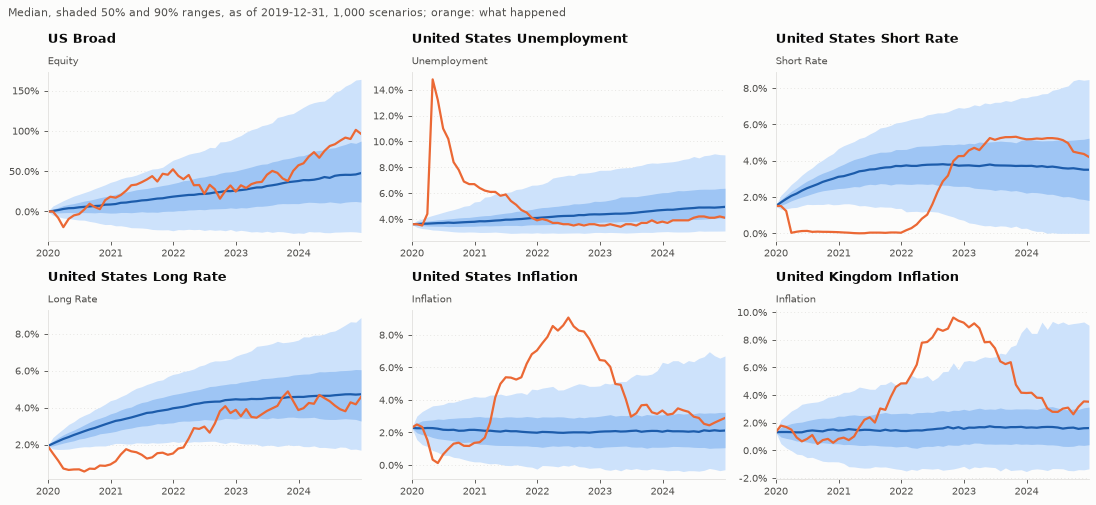

In [10]:
pandemic = scenarios.out_of_sample(as_of="2019-12-31", years=5, n_simulations=1000, seed=42, factors=factors)
pandemic.plot(factors)

In [11]:
pandemic.table.select("factor", "date", "realized", "p5", "p50", "p95", "pit")

factor,date,realized,p5,p50,p95,pit
str,date,f64,f64,f64,f64,f64
"""united_states_inflation""",2020-12-31,0.0136,0.0020,0.0216,0.0421,0.2520
"""united_states_inflation""",2021-12-31,0.0704,-0.0025,0.0198,0.0462,0.9870
"""united_states_inflation""",2022-12-31,0.0645,-0.0016,0.0205,0.0486,0.9730
"""united_states_inflation""",2023-12-31,0.0335,-0.0030,0.0205,0.0631,0.7920
"""united_states_inflation""",2024-12-31,0.0289,-0.0029,0.0212,0.0670,0.6830
"""united_kingdom_inflation""",2020-12-31,0.0083,-0.0083,0.0143,0.0400,0.3350
"""united_kingdom_inflation""",2021-12-31,0.0484,-0.0139,0.0140,0.0488,0.9480
"""united_kingdom_inflation""",2022-12-31,0.0924,-0.0116,0.0155,0.0644,0.9740
"""united_kingdom_inflation""",2023-12-31,0.0415,-0.0153,0.0164,0.0894,0.8750


In [12]:
pandemic.scores.select("factor", "coverage_50", "coverage_90", "pit_mean", "crps_skill")

factor,coverage_50,coverage_90,pit_mean,crps_skill
str,f64,f64,f64,f64
"""united_states_inflation""",0.4000,0.6000,0.7374,0.1812
"""united_kingdom_inflation""",0.2000,0.8000,0.7862,0.3132
"""united_states_short_rate""",0.4000,0.6000,0.3950,0.3867
"""united_states_long_rate""",0.6000,0.6000,0.2366,0.3599
"""united_states_unemployment""",0.4000,0.8000,0.4122,-0.0639
"""us_broad""",0.6000,1.0000,0.7170,0.6865


Here the cloud holds more. US stocks stay inside the 90% band in all five years, through the 2020 crash and the
rally after it. The jump in US unemployment to 6.7% at the end of 2020 is above the band's 5.32%, and the cut to
zero again lies below it: the short rate at 0.07% and 0.03% at the end of 2020 and 2021 against 5th percentiles
of 1.59% and 1.38%, the 10-year rate at 0.92% and 1.51% against 1.99% and 2.17%. The inflation that followed
sits at the edge: US inflation of 7.04% at the end of 2021 and 6.45% at the end of 2022 is above the 95th
percentiles of 4.62% and 4.86%, and UK inflation of 4.84% in 2021 lands just inside its 4.88% before 9.24% in
2022 goes past 6.44%. From 2022 on, both rates are back inside the band.

## Step 7: every four years since 2003

One crisis is an anecdote. Five origins four years apart, each run four years ahead, score every year from 2004
to 2023 once, with one row per factor across them.

In [13]:
evaluation = scenarios.out_of_sample_many(
    origins=["2003-12-31", "2007-12-31", "2011-12-31", "2015-12-31", "2019-12-31"],
    years=4,
    n_simulations=1000,
    seed=42,
)
evaluation.scores.select(
    "factor", "origins", "coverage_50", "coverage_90", "bands", "pit_mean", "pit_std", "crps_skill", "tails"
)

factor,origins,coverage_50,coverage_90,bands,pit_mean,pit_std,crps_skill,tails
str,i64,f64,f64,str,f64,f64,f64,str
"""united_states_inflation""",5,0.4000,0.8500,"""ok""",0.5515,0.3003,0.4599,"""low too fat"""
"""eurozone_inflation""",5,0.5000,0.8500,"""ok""",0.4902,0.2912,0.4115,"""ok"""
"""united_kingdom_inflation""",5,0.6500,0.9000,"""ok""",0.6405,0.2033,0.4094,"""low too fat"""
"""united_states_short_rate""",5,0.2500,0.7000,"""too narrow""",0.2189,0.2252,0.0560,"""low too thin"""
"""united_states_long_rate""",5,0.4000,0.7000,"""too narrow""",0.1900,0.1591,-0.6750,"""low too thin"""
"""eurozone_short_rate""",5,0.2000,0.4000,"""too narrow""",0.1979,0.2974,0.1931,"""low too thin"""
"""eurozone_long_rate""",5,0.1500,0.6500,"""too narrow""",0.1614,0.2167,-0.1970,"""ok"""
"""united_kingdom_short_rate""",5,0.2500,0.3500,"""too narrow""",0.1208,0.1825,-0.5277,"""ok"""
"""united_kingdom_long_rate""",5,0.1000,0.5500,"""too narrow""",0.1134,0.1618,-0.6651,"""ok"""


Inflation holds best: US, euro-area and UK inflation keep 85% to 90% of their years inside the 90% band, close to
the 0.9 it should hold, and US stocks hold 0.90. The rates hold worst, and they lean one way: with PIT means of
0.11 to 0.22, the six short and long rates ended below the scenarios' middle in most years, and their 90% bands
held between 0.35 (the UK short rate) and 0.70 (both US rates). That is the honest result of reading what was
known at each origin. Most neutral-rate estimates published before 2019 sat above today's, so the fitted policy
rules expected rates to return to normal, as the FOMC's projections did through the 2010s, while rates stayed near
zero for much of the period; on CRPS the UK rates and the US and euro-area 10-year rates lose to a no-change
forecast. Unemployment's bands are too narrow as well (0.50 to 0.65), as are the yen's (0.70) and US house
prices' (0.55); the euro's is too wide (1.00).

## Recap

- Over 30 years, 15 of the 26 macro relationships pass and 11 warn; the weak links are unemployment's pull on
  rates, on stocks and on inflation.
- Against their longest records, every factor warns or fails somewhere, mostly on tails thinner than history's.
- Four parameter guardrails warn, Japan's equity regimes furthest from the long record.
- Fitted on what was known at the end of 2007, the model missed the speed of 2008: unemployment, the rate cuts
  and the fall in stocks all left the 90% band, and the rule, reading the 2.14% neutral rate of the time, expected
  rates well above 5%. Fitted at the end of 2019, stocks stayed inside while the cut to zero and the 2021-22
  inflation surge did not.
- From 2004 to 2023, inflation and US stocks keep about nine years in ten inside their 90% bands; the rates, fitted
  on the neutral rates of their time, ended below the scenarios' middle in most years, and unemployment, the yen
  and house prices are too narrow.

Every check is described in the
[validation documentation](https://www.jeroenbouma.com/projects/financescenarios/docs/validation). Back to the
start: [**0. README Examples**](FinanceScenarios%20-%200.%20README%20Examples.ipynb).